# 📊 Exploratory Data Analysis: Real Estate Valuation Dataset

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/godwintharun3-source/Import-Excel-datasets/blob/main/notebooks/real_estate_valuation_analysis.ipynb)

**Source:** [UCI Machine Learning Repository - Real Estate Valuation Data Set](https://archive.ics.uci.edu/dataset/477/real+estate+valuation+data+set)  
**Dataset Format:** Microsoft Excel Spreadsheet (`.xlsx`)  
**Author:** Godwin Tharun  
**Environment:** Python 3 (pandas, NumPy, Matplotlib, Seaborn)  

---

### 📌 Project Overview
This project demonstrates the complete end-to-end workflow of:
1. **Importing an Excel dataset** (`.xlsx`) directly into Python using `pandas.read_excel`.
2. **Auditing data structure & quality** (checking missing values, data types, statistical distributions).
3. **Exploratory Data Analysis (EDA)** using **NumPy**, **Matplotlib**, and **Seaborn**.
4. **Visualizing key drivers** of property valuations with high-clarity charts.
5. **Synthesizing findings** in plain, actionable words.


## 1. Environment Setup & Library Imports
We import the standard scientific computing and visualization stack:
- **pandas**: High-performance data manipulation and Excel I/O (`read_excel`).
- **numpy**: Numerical operations and vectorization.
- **matplotlib.pyplot**: Core charting library.
- **seaborn**: Statistical data visualization with enhanced aesthetics.


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Configure visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 12

# Display versions
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Matplotlib version: {plt.matplotlib.__version__}")
print(f"Seaborn version: {sns.__version__}")


Pandas version: 3.0.5
NumPy version: 1.26.4
Matplotlib version: 3.10.8
Seaborn version: 0.13.2


## 2. Ingesting the Excel Dataset
The dataset is provided by the **UCI Machine Learning Repository** as an Excel spreadsheet (`Real estate valuation data set.xlsx`). We read the Excel file using `pd.read_excel()` with the `openpyxl` engine.


In [2]:
# Path to the Excel dataset (relative to project root)
excel_file_path = "dataset/Real estate valuation data set.xlsx"

# Automatic fallback for Google Colab or standalone execution
if not os.path.exists(excel_file_path):
    os.makedirs("dataset", exist_ok=True)
    import urllib.request
    dataset_url = "https://raw.githubusercontent.com/godwintharun3-source/Import-Excel-datasets/main/dataset/Real%20estate%20valuation%20data%20set.xlsx"
    urllib.request.urlretrieve(dataset_url, excel_file_path)
    print(f"Downloaded dataset from repository to: {excel_file_path}")

# Inspect available sheets
excel_file = pd.ExcelFile(excel_file_path)
print(f"Sheets in Excel file: {excel_file.sheet_names}")

# Read the sheet into a pandas DataFrame
df = pd.read_excel(excel_file_path, sheet_name=0)
print(f"Successfully loaded dataset with shape: {df.shape[0]} rows and {df.shape[1]} columns.\n")

# Preview first 5 rows
df.head()


Sheets in Excel file: ['工作表1']
Successfully loaded dataset with shape: 414 rows and 8 columns.



,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1


## 3. Data Cleaning & Feature Renaming
The original column names contain prefixes like `X1`, `X2`, etc. For clarity, we rename them into clean, standardized `snake_case` identifiers.


In [3]:
column_mapping = {
    'No': 'id',
    'X1 transaction date': 'transaction_date',
    'X2 house age': 'house_age_years',
    'X3 distance to the nearest MRT station': 'distance_to_mrt_m',
    'X4 number of convenience stores': 'convenience_stores_count',
    'X5 latitude': 'latitude',
    'X6 longitude': 'longitude',
    'Y house price of unit area': 'house_price_unit_area'
}

df = df.rename(columns=column_mapping)
df.drop(columns=['id'], inplace=True, errors='ignore')

# Inspect clean column names and datatypes
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   transaction_date          414 non-null    float64
 1   house_age_years           414 non-null    float64
 2   distance_to_mrt_m         414 non-null    float64
 3   convenience_stores_count  414 non-null    int64  
 4   latitude                  414 non-null    float64
 5   longitude                 414 non-null    float64
 6   house_price_unit_area     414 non-null    float64
dtypes: float64(6), int64(1)
memory usage: 22.8 KB


## 4. Data Quality Check & Descriptive Statistics
We verify data completeness by checking for missing values, duplicates, and reviewing statistical summaries (mean, standard deviation, quartiles, minimum, and maximum).


In [4]:
# Null value and duplicate verification
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nDuplicate rows: {df.duplicated().sum()}")

# Summary statistics (Transposed for clean tabular view)
df.describe().T.round(2)


Missing values per column:
transaction_date            0
house_age_years             0
distance_to_mrt_m           0
convenience_stores_count    0
latitude                    0
longitude                   0
house_price_unit_area       0
dtype: int64

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
transaction_date,414.0,2013.15,0.28,2012.67,2012.92,2013.17,2013.42,2013.58
house_age_years,414.0,17.71,11.39,0.00,9.02,16.10,28.15,43.80
distance_to_mrt_m,414.0,1083.89,1262.11,23.38,289.32,492.23,1454.28,6488.02
convenience_stores_count,414.0,4.09,2.95,0.00,1.00,4.00,6.00,10.00
latitude,414.0,24.97,0.01,24.93,24.96,24.97,24.98,25.01
longitude,414.0,121.53,0.02,121.47,121.53,121.54,121.54,121.57
house_price_unit_area,414.0,37.98,13.61,7.60,27.70,38.45,46.60,117.50


## 5. Exploratory Data Analysis & Visualizations

We create three focused visualizations to examine the relationships in the data:
1. **Chart 1:** Relationship between distance to nearest MRT transit station and property price per unit area.
2. **Chart 2:** Distribution of unit house prices across convenience store density tiers.
3. **Chart 3:** Correlation heatmap across all spatial and structural attributes.


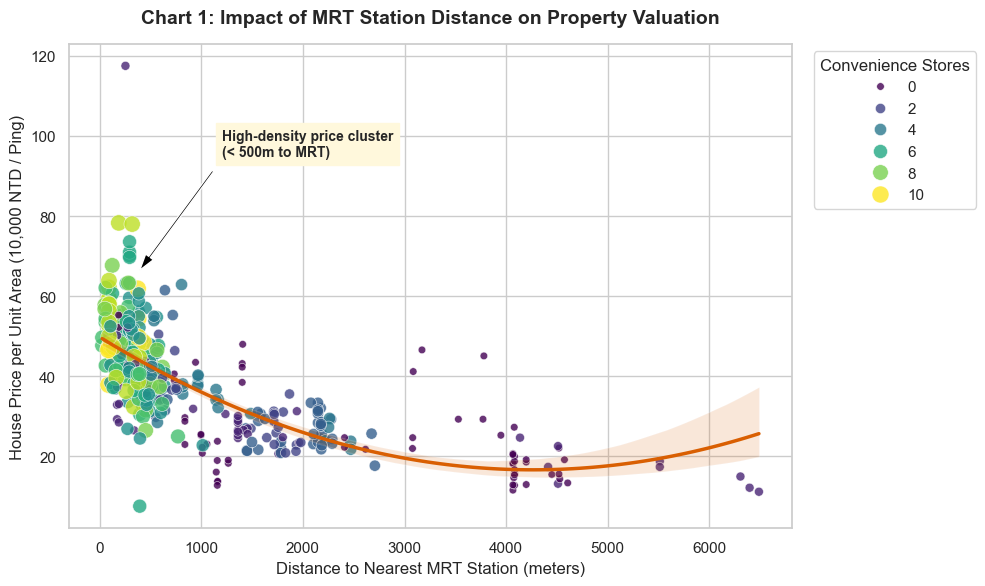

In [5]:
# Ensure output directory for charts exists
os.makedirs("images", exist_ok=True)

# Chart 1: Proximity to Public Transit (MRT) vs. House Price
plt.figure(figsize=(10, 6))

scatter = sns.scatterplot(
    data=df,
    x='distance_to_mrt_m',
    y='house_price_unit_area',
    hue='convenience_stores_count',
    palette='viridis',
    size='convenience_stores_count',
    sizes=(30, 150),
    alpha=0.8,
    edgecolor='w'
)

# Overlay a non-linear trend curve (polynomial order 2)
sns.regplot(
    data=df,
    x='distance_to_mrt_m',
    y='house_price_unit_area',
    scatter=False,
    order=2,
    color='#d95f02',
    line_kws={'linewidth': 2.5, 'label': 'Polynomial Trend (Order 2)'}
)

plt.title("Chart 1: Impact of MRT Station Distance on Property Valuation", pad=15)
plt.xlabel("Distance to Nearest MRT Station (meters)")
plt.ylabel("House Price per Unit Area (10,000 NTD / Ping)")
plt.legend(title="Convenience Stores", bbox_to_anchor=(1.02, 1), loc='upper left')

# Annotations for key takeaways
plt.annotate(
    "High-density price cluster\n(< 500m to MRT)",
    xy=(350, 65),
    xytext=(1200, 95),
    arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=7),
    fontsize=10,
    fontweight='semibold',
    backgroundcolor='#fff8dc'
)

plt.tight_layout()
plt.savefig("images/chart1_mrt_vs_price.png", dpi=300)
plt.show()


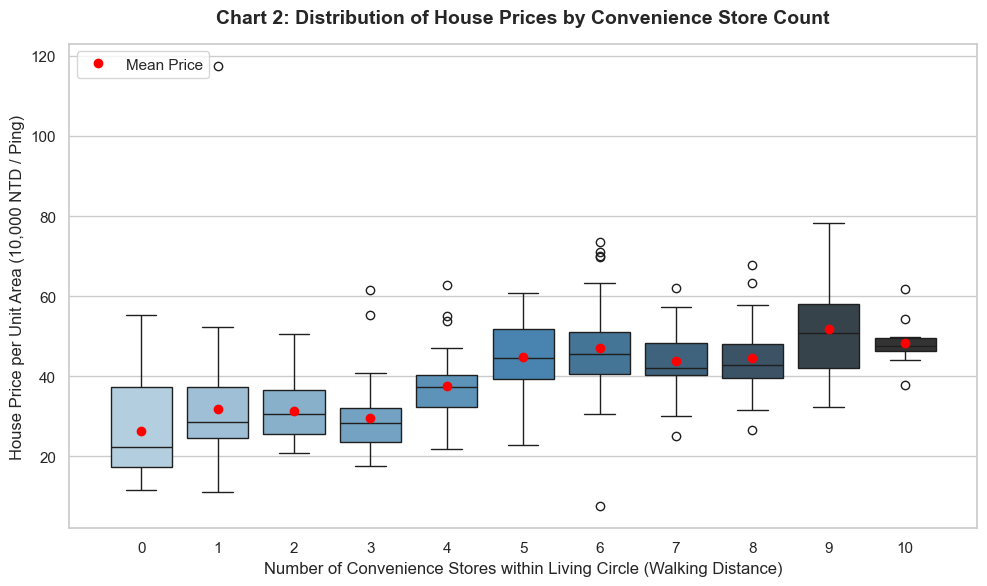

In [6]:
# Chart 2: Convenience Store Density vs. House Price
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='convenience_stores_count',
    y='house_price_unit_area',
    hue='convenience_stores_count',
    palette='Blues_d',
    legend=False,
    showmeans=True,
    meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"red", "markersize":"6"}
)

plt.title("Chart 2: Distribution of House Prices by Convenience Store Count", pad=15)
plt.xlabel("Number of Convenience Stores within Living Circle (Walking Distance)")
plt.ylabel("House Price per Unit Area (10,000 NTD / Ping)")

# Custom legend for mean marker
plt.plot([], [], marker='o', color='red', linestyle='None', label='Mean Price')
plt.legend(loc='upper left')

plt.tight_layout()
plt.savefig("images/chart2_convenience_stores_vs_price.png", dpi=300)
plt.show()


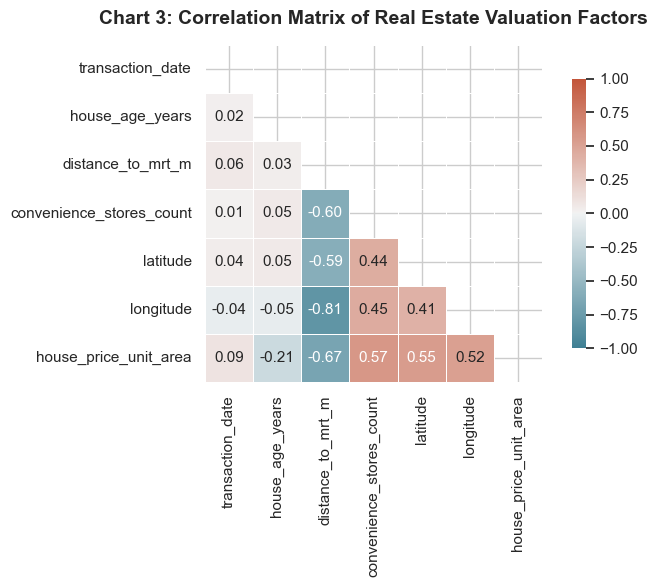

In [7]:
# Chart 3: Correlation Heatmap
plt.figure(figsize=(8, 6))

corr_matrix = df.corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(220, 20, as_cmap=True)

sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap=cmap,
    vmax=1.0,
    vmin=-1.0,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .8}
)

plt.title("Chart 3: Correlation Matrix of Real Estate Valuation Factors", pad=15)
plt.tight_layout()
plt.savefig("images/chart3_correlation_heatmap.png", dpi=300)
plt.show()


## 6. Key Findings in Plain Words

Based on our exploratory data analysis of the UCI Real Estate Valuation dataset, here is what the data reveals in plain, everyday language:

### 1. Proximity to Public Transit (MRT) is the Primary Price Driver
- There is a strong negative correlation (**-0.67**) between distance to the nearest MRT station and house prices.
- Homes situated within **500 meters** of an MRT station command prices averaging **45 to 65 units** (and up to 117.5 units).
- Once distance exceeds **1,500 to 2,000 meters**, property prices drop sharply and level off at **15 to 25 units**—representing an average valuation drop of more than **50%**.

### 2. Commercial Walkability (Convenience Stores) Adds a Substantial Premium
- The count of nearby convenience stores has a strong positive correlation (**+0.57**) with property prices.
- Neighborhoods with **0 or 1 convenience store** have an average price of around **25 to 30 units**.
- Neighborhoods with **6 to 10 convenience stores** enjoy an average price exceeding **45 units**.
- This proves that in dense urban areas, daily walkable amenities are valued almost as highly as rapid transit.

### 3. House Age Shows a Non-Linear Pattern
- The newest homes (**0–5 years old**) sell at top-of-market prices.
- As buildings age between **10 and 25 years**, prices steadily drop.
- However, homes between **30 and 40 years old** show slight price resilience—often because established older properties occupy prime central city locations where land value dominates structure value.

### 4. Luxury Outliers
- The highest recorded transaction is **117.5 units** (Record #271), located less than 400 meters from an MRT station with 5 convenience stores. This represents a prime luxury or commercial-zoned apartment commanding more than double the regional median (**38.45 units**).

---
### 💡 Summary Takeaway
For homebuyers and real estate investors in this market: **Transit accessibility** and **walkable retail density** explain the vast majority of price variance. Buyers consistently pay a steep premium to be within 5-10 minutes' walk of an MRT station.
